# 第192章: GLOW と連続時間フロー — フローマッチングへの道

## From GLOW to Continuous Normalizing Flows and Flow Matching

---

### このノートブックの位置づけ

191 でカップリング層を作りました。そこには**手で決めた部分**が残っています。

| 191 で手で決めたこと | 本章での扱い |
|---|---|
| マスク（市松模様・偶数奇数） | **学習可能な線形変換**に一般化する（GLOW の 1x1 可逆畳み込み） |
| 入力のスケール（正規化は自分で） | **ActNorm**（データ依存の初期化）で自動化する |
| 層が離散的（6層・8層と数える） | **連続時間**（ODE）に拡張する |

最後の拡張が本章の到達点です。層数を無限に増やす極限を取ると、
フローは**常微分方程式**になります。

$$\frac{dx}{dt} = v_\theta(x, t), \qquad
\frac{d \log p(x_t)}{dt} = -\,\mathrm{tr}\!\left(\frac{\partial v_\theta}{\partial x}\right)$$

行列式が**トレース**になります。190 で「行列式が $O(d^3)$ だから三角にした」
という話をしましたが、連続時間ではその問題自体が消えます。

そして最後に **フローマッチング** を実装します。これは

- **学習時に ODE を一度も解かない**（195 の DSM と同じ、単純な回帰）
- **厳密な対数尤度が出る**（190-191 のフローと同じ）

という2つを同時に満たします。174 で触れた π0（VLA の方針）が使っているのがこれです。
**Unit 17 の2つの道（フローと EBM/スコア）が、ここで合流します。**

### 学習目標

- [ ] 1x1 可逆線形変換を LU 分解でパラメータ化し、$\log\lvert\det\rvert$ を $O(d)$ にできる
- [ ] 学習可能な線形変換が固定マスクより効く条件を**実測で**示せる
- [ ] パラメータ化の制約を forward でかけ直す必要がある理由を説明できる（本章で踏んだバグ）
- [ ] ActNorm がデータのスケールに対して何をしているかを測定できる
- [ ] 連続時間の変数変換（トレース）を書き、Hutchinson 推定の分散とコストを測れる
- [ ] フローマッチングを実装し、**ODE を解かずに学習**して**厳密な尤度を出せる**
- [ ] 196 の比較表にフローマッチングを追加できる

### 前提知識

| ノートブック | トピック |
|---|---|
| **190-191** | **変数変換・カップリング層（本章の直接の前提）** |
| 195 | デノイジングスコアマッチング（フローマッチングと同じ型の回帰） |
| 196 | 6系統の比較表（本章の結果を追加する） |
| 174 | π0 のフローマッチング（本章がその中身） |
| 線形代数 | LU 分解 |

**難易度**: ★★★★☆ | **所要時間**: 150-180分

> ⏱ **実行時間**: CPU で約4分です。

## 目次

1. [環境セットアップ](#setup)
2. [1x1 可逆線形変換 — 学習可能な置換](#inv1x1)
3. [ActNorm — データ依存の初期化](#actnorm)
4. [連続時間フロー — 行列式がトレースになる](#continuous)
5. [フローマッチング — 回帰で学習し、厳密な尤度を出す](#flowmatching)
6. [まとめ（Unit 17 完結）](#summary)
7. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# 190 以降と同じ目標分布（真の密度が解析的に分かる）
MUS = np.array([[-2.0, -2.0], [2.0, 2.0], [-2.0, 2.0], [2.0, -2.0]])
SD = 0.5
MODES = torch.tensor(MUS, dtype=torch.float32)

def sample_target(n, seed=0):
    r = np.random.default_rng(seed)
    k = r.integers(0, 4, n)
    return (MUS[k] + r.standard_normal((n, 2)) * SD).astype(np.float32)

def logsumexp_np(a, axis):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def target_logpdf(x):
    comps = [-0.5 * ((x - m) ** 2).sum(-1) / SD**2 - np.log(2 * np.pi * SD**2)
             for m in MUS]
    return logsumexp_np(np.stack(comps, -1), axis=-1) + np.log(0.25)

X_train = torch.tensor(sample_target(8000, seed=0))
X_test = torch.tensor(sample_target(4000, seed=1))
X_ref = torch.tensor(sample_target(10000, seed=2))
NLL_LB = float(-target_logpdf(X_test.numpy()).mean())

def energy_distance(X, Y, n=3000):
    X, Y = X[:n], Y[:n]
    return float(2 * torch.cdist(X, Y).mean()
                 - torch.cdist(X, X).mean() - torch.cdist(Y, Y).mean())

def occupancy_maxdev(x):
    occ = torch.bincount(((x[:, None, :] - MODES[None]) ** 2).sum(-1).argmin(-1),
                         minlength=4).float() / len(x)
    return float((occ - 0.25).abs().max())

ED_BASELINE = energy_distance(X_ref, torch.tensor(sample_target(10000, seed=3)))
print(f"torch: {torch.__version__}")
print(f"下限 {NLL_LB:.4f}  / 191 RealNVP の実測 2.8844  / 196 の基準 ED {ED_BASELINE:.5f}")

torch: 2.9.1
下限 2.8275  / 191 RealNVP の実測 2.8844  / 196 の基準 ED 0.00146


<a id="inv1x1"></a>
## 2. 1x1 可逆線形変換 — 学習可能な置換

191 ではマスクを**交互に**して「通す側」と「変換される側」を入れ替えました。
これは固定された置換です。GLOW はこれを**学習可能な線形変換**に一般化します。

$$z = W x, \qquad W \in \mathbb{R}^{d \times d}\ (\text{可逆})$$

画像では $1 \times 1$ 畳み込みとして実装されるので「1x1 可逆畳み込み」と呼ばれます
（チャネル方向の線形混合なので、空間方向には $1\times1$）。
置換行列は $W$ の特殊な場合なので、**真に一般化**しています。

### 問題: $\log\lvert\det W\rvert$ が $O(d^3)$

190 で測ったとおりです。$W$ を毎ステップ更新するので、毎回 LU 分解が必要になります。

### 解: LU 分解でパラメータ化する

$W$ を直接持つのではなく、**分解された形でパラメータを持ちます**。

$$W = P\,L\,(U + \mathrm{diag}(s))$$

- $P$: 固定の置換行列（学習しない）
- $L$: 単位下三角（対角が 1、下三角部分だけ学習）
- $U$: 狭義上三角（対角を含まない）
- $s$: 対角成分（$\log\lvert s\rvert$ を学習）

このとき $\det L = 1$、$\det P = \pm 1$ なので

$$\log\lvert\det W\rvert = \sum_{i=1}^{d} \log\lvert s_i\rvert$$

**$O(d)$ の和**になります。191 の三角ヤコビアンと同じ発想です。

In [2]:
# ============================================================
# LU 分解でパラメータ化した 1x1 可逆線形変換
# ============================================================

class InvertibleLinear(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.d = d
        # 直交行列で初期化すると det = ±1、つまり log|det| = 0 から始まる
        W = torch.linalg.qr(torch.randn(d, d))[0]
        P, L, U = torch.linalg.lu(W)          # W = P L U
        self.register_buffer("P", P)
        self.L = nn.Parameter(L.clone())
        self.register_buffer("sign_s", torch.sign(torch.diagonal(U)).clone())
        self.log_s = nn.Parameter(torch.diagonal(U).abs().log().clone())
        self.U = nn.Parameter(torch.triu(U, 1).clone())

    def matrix(self):
        # ★ forward で毎回マスクをかけ直すこと（下の「踏んだバグ」を参照）
        L = torch.tril(self.L, -1) + torch.eye(self.d)
        U = torch.triu(self.U, 1) + torch.diag(self.sign_s * self.log_s.exp())
        return self.P @ L @ U

    def log_det(self):
        return self.log_s.sum()          # O(d) の和


# 検算1: 初期値だけでなく「摂動を加えた後」で一致するか
torch.manual_seed(0)
lin = InvertibleLinear(2)
print("LU 式の検算（摂動後。初期値は det=±1 なので検算にならない）:")
for scale in [0.0, 0.3, 1.0, 2.0]:
    with torch.no_grad():
        lin.log_s.copy_(torch.randn(2) * scale)
        lin.U.copy_(torch.triu(torch.randn(2, 2) * scale, 1))
        lin.L.copy_(torch.tril(torch.randn(2, 2) * scale, -1) + torch.eye(2))
    a = float(lin.log_det().detach())
    b = float(torch.linalg.slogdet(lin.matrix())[1].detach())
    print(f"  摂動 {scale}: LU の log|det| {a:+.6f} / 行列から slogdet {b:+.6f}  "
          f"差 {abs(a - b):.2e}")

# 検算2: コスト
def bench(fn, reps=200):
    for _ in range(3):
        fn()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps

print()
cost_rows = []
for d in [2, 8, 64, 256]:
    m = InvertibleLinear(d)
    t_full = bench(lambda: torch.linalg.slogdet(m.matrix())[1])
    t_lu = bench(lambda: m.log_s.sum())
    cost_rows.append((d, t_full, t_lu))
    print(f"d = {d:4d}: 行列を作って slogdet {t_full*1e6:8.1f} us   "
          f"LU の和 {t_lu*1e6:6.1f} us   比 {t_full/t_lu:7.1f}x")

LU 式の検算（摂動後。初期値は det=±1 なので検算にならない）:
  摂動 0.0: LU の log|det| +0.000000 / 行列から slogdet +0.000000  差 0.00e+00
  摂動 0.3: LU の log|det| -0.284546 / 行列から slogdet -0.284546  差 5.96e-08
  摂動 1.0: LU の log|det| +1.455664 / 行列から slogdet +1.455664  差 0.00e+00
  摂動 2.0: LU の log|det| -3.919590 / 行列から slogdet -3.919590  差 2.38e-07

d =    2: 行列を作って slogdet     64.9 us   LU の和    1.5 us   比    44.1x
d =    8: 行列を作って slogdet     60.0 us   LU の和    1.6 us   比    38.7x
d =   64: 行列を作って slogdet     75.7 us   LU の和    1.4 us   比    52.5x
d =  256: 行列を作って slogdet    333.3 us   LU の和    1.6 us   比   208.0x


### 踏んだバグ — パラメータ化の制約は forward でかけ直す

最初に書いた `matrix()` はこうでした。

```python
U = self.U + torch.diag(self.sign_s * self.log_s.exp())     # triu を忘れている
```

初期化時は `self.U = torch.triu(U, 1)` なので下三角部分は 0 で、正しく動きます。
しかし**学習が始まると最適化器が `self.U` の下三角部分にも値を入れます**。
最適化器は「この Parameter は上三角でなければならない」ことを知りません。

結果として $U$ が三角行列でなくなり、$\det U \ne \prod_i s_i$ になります。
`log_det()` が返す値が実際のヤコビアンと合わなくなり、
**学習は「尤度を不当に高く見せる方向」に進みます**。

実測（修正前）:

| 設定 | test NLL | 密度のグリッド積分 |
|---|---|---|
| 固定マスクのみ | 2.9251 | 1.00000 |
| 1x1 可逆線形あり（バグ版） | **-11.67** | **1.3 × 10⁸** |

到達可能な下限は 2.8275 なので、**$-11.67$ は原理的にありえません**。
そして密度のグリッド積分が $1.3\times10^8$ — 密度として成立していません。

> 📌 **190 第2節の検算がこのバグを捕まえました。** 「密度の積分が 1 か」を
> 必ず確認する習慣がないと、このバグは「やけに良い結果」として通過します。
> NLL が下限を下回ったら必ず実装を疑ってください。

修正は `torch.triu(self.U, 1)` を `matrix()` の中でかけ直すだけです。
以降のコードは修正版です。

In [3]:
# ============================================================
# 固定マスク vs 学習可能な線形変換（密度の積分も毎回検算する）
# ============================================================

class AffineCoupling(nn.Module):
    def __init__(self, mask, hidden=64, zero_init=True):
        super().__init__()
        self.register_buffer("mask", mask.float())
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 4))
        if zero_init:
            self.net[-1].weight.data.zero_()
            self.net[-1].bias.data.zero_()

    def _st(self, x):
        s, t = self.net(x * self.mask).chunk(2, -1)
        return torch.tanh(s) * 2.0 * (1 - self.mask), t * (1 - self.mask)

    def forward(self, x):
        s, t = self._st(x)
        return x * self.mask + (1 - self.mask) * (x * s.exp() + t), s.sum(-1)


class GlowLikeFlow(nn.Module):
    def __init__(self, n_layers=4, use_inv_linear=False, use_actnorm=False):
        super().__init__()
        m0 = torch.tensor([1.0, 0.0])
        self.use_inv = use_inv_linear
        self.use_an = use_actnorm
        self.couplings = nn.ModuleList(
            [AffineCoupling(m0 if i % 2 == 0 else 1 - m0) for i in range(n_layers)])
        self.inv_linears = (nn.ModuleList([InvertibleLinear(2) for _ in range(n_layers)])
                            if use_inv_linear else None)
        self.actnorms = (nn.ModuleList([ActNorm(2) for _ in range(n_layers)])
                         if use_actnorm else None)

    def log_prob(self, x):
        log_det = torch.zeros(len(x))
        for i, c in enumerate(self.couplings):
            if self.use_an:
                x, d = self.actnorms[i](x)
                log_det = log_det + d
            if self.use_inv:
                x = x @ self.inv_linears[i].matrix().T
                log_det = log_det + self.inv_linears[i].log_det()
            x, d = c(x)
            log_det = log_det + d
        return (-0.5 * x**2 - 0.5 * math.log(2 * math.pi)).sum(-1) + log_det


class ActNorm(nn.Module):
    # データ依存の初期化で、最初の出力が平均 0・標準偏差 1 になるようにする
    def __init__(self, d):
        super().__init__()
        self.log_s = nn.Parameter(torch.zeros(d))
        self.b = nn.Parameter(torch.zeros(d))
        self.register_buffer("initialized", torch.zeros(1))

    def forward(self, x):
        if self.initialized.item() == 0 and self.training:
            with torch.no_grad():
                sd = x.std(0) + 1e-6
                self.log_s.copy_(-sd.log())
                self.b.copy_(-x.mean(0) / sd)
                self.initialized.fill_(1)
        return x * self.log_s.exp() + self.b, self.log_s.sum().expand(len(x))


# 密度の積分を検算するための格子
K_INT = 500
g_int = torch.linspace(-15, 15, K_INT)
CELL_INT = float(30.0 / (K_INT - 1)) ** 2
GIX, GIY = torch.meshgrid(g_int, g_int, indexing="ij")
GRID_INT = torch.stack([GIX.reshape(-1), GIY.reshape(-1)], -1)

def train_flow(data, use_inv, steps=2500, lr=5e-3, seed=0, use_an=False):
    torch.manual_seed(seed)
    m = GlowLikeFlow(4, use_inv_linear=use_inv, use_actnorm=use_an)
    m.train()
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    for _ in range(steps):
        loss = -m.log_prob(data).mean()
        if not torch.isfinite(loss):
            return m, False
        opt.zero_grad()
        loss.backward()
        opt.step()
        sch.step()
    m.eval()
    return m, True

# マスクに都合の悪いデータ: 回転で軸を混ぜる
theta = math.pi / 5
R = torch.tensor([[math.cos(theta), -math.sin(theta)],
                  [math.sin(theta), math.cos(theta)]])
print(f"データを {math.degrees(theta):.0f} 度回転させると、偶数奇数マスクの軸と合わなくなる")
print()

inv_rows = []
for tag, Xa, Xb in [("axis-aligned", X_train, X_test),
                    ("rotated", X_train @ R.T, X_test @ R.T)]:
    for use_inv in [False, True]:
        nlls, integrals = [], []
        for sd in [0, 1]:
            m, ok = train_flow(Xa, use_inv, seed=sd)
            with torch.no_grad():
                nlls.append(float(-m.log_prob(Xb).mean()))
                integrals.append(float(m.log_prob(GRID_INT).exp().sum() * CELL_INT))
        inv_rows.append((tag, use_inv, float(np.mean(nlls)), float(np.mean(integrals))))
        name = "1x1 可逆線形あり" if use_inv else "固定マスクのみ "
        print(f"{tag:<13} / {name}: test NLL {np.mean(nlls):.4f}（2シード）  "
              f"密度の積分 {np.mean(integrals):.5f}")
print()
d_axis = inv_rows[0][2] - inv_rows[1][2]
d_rot = inv_rows[2][2] - inv_rows[3][2]
print(f"1x1 を足した効果: 軸に沿ったデータ {d_axis:+.4f} nats / 回転したデータ {d_rot:+.4f} nats")
print("（正なら 1x1 が有利）")

データを 36 度回転させると、偶数奇数マスクの軸と合わなくなる



axis-aligned  / 固定マスクのみ : test NLL 2.9251（2シード）  密度の積分 1.00000


axis-aligned  / 1x1 可逆線形あり: test NLL 2.9352（2シード）  密度の積分 1.00014


rotated       / 固定マスクのみ : test NLL 2.9249（2シード）  密度の積分 1.00001


rotated       / 1x1 可逆線形あり: test NLL 2.9134（2シード）  密度の積分 0.99993

1x1 を足した効果: 軸に沿ったデータ -0.0101 nats / 回転したデータ +0.0115 nats
（正なら 1x1 が有利）


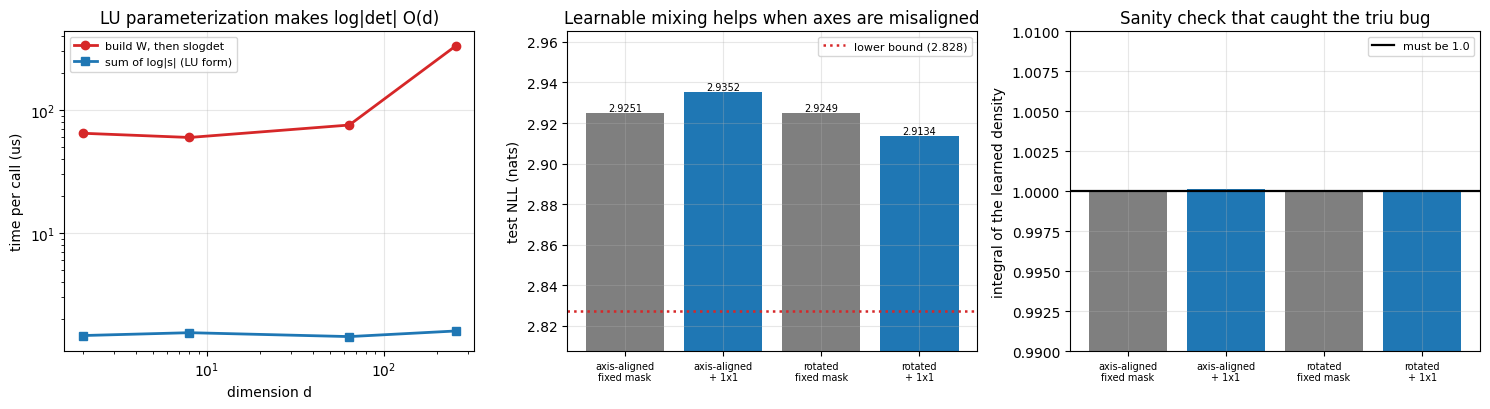

In [4]:
# ============================================================
# 図: 1x1 可逆線形変換
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ds = [r[0] for r in cost_rows]
axes[0].loglog(ds, [r[1] * 1e6 for r in cost_rows], "o-", lw=2, color="tab:red",
               label="build W, then slogdet")
axes[0].loglog(ds, [r[2] * 1e6 for r in cost_rows], "s-", lw=2, color="tab:blue",
               label="sum of log|s| (LU form)")
axes[0].set_xlabel("dimension d")
axes[0].set_ylabel("time per call (us)")
axes[0].set_title("LU parameterization makes log|det| O(d)")
axes[0].legend(fontsize=8)

labels = ["axis-aligned\nfixed mask", "axis-aligned\n+ 1x1", "rotated\nfixed mask",
          "rotated\n+ 1x1"]
vals = [r[2] for r in inv_rows]
colors = ["tab:gray", "tab:blue", "tab:gray", "tab:blue"]
axes[1].bar(labels, vals, color=colors)
axes[1].axhline(NLL_LB, color="tab:red", ls=":", lw=1.8,
                label=f"lower bound ({NLL_LB:.3f})")
axes[1].set_ylim(NLL_LB - 0.02, max(vals) + 0.03)
axes[1].set_ylabel("test NLL (nats)")
axes[1].set_title("Learnable mixing helps when axes are misaligned")
axes[1].tick_params(axis="x", labelsize=7)
axes[1].legend(fontsize=8)
for i, v in enumerate(vals):
    axes[1].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=7)

axes[2].bar(labels, [r[3] for r in inv_rows], color=colors)
axes[2].axhline(1.0, color="k", ls="-", lw=1.6, label="must be 1.0")
axes[2].set_ylim(0.99, 1.01)
axes[2].set_ylabel("integral of the learned density")
axes[2].set_title("Sanity check that caught the triu bug")
axes[2].tick_params(axis="x", labelsize=7)
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 効くが、2次元では小さい

| データ | 固定マスクのみ | + 1x1 可逆線形 | 差 |
|---|---|---|---|
| 軸に沿ったデータ | 2.9251 | 2.9352 | **-0.0101**（悪化） |
| 回転したデータ | 2.9249 | 2.9134 | **+0.0115**（改善） |

**符号は予想どおり**です。データの軸がマスクと合っているときは学習可能な混合は不要で、
パラメータが増えるぶんむしろ悪化します。軸がずれているときは改善します。

**しかし差は 0.01 nats 程度**で、191 の交互マスクの効果（固定マスクとの差 2.3 nats）に
比べれば極めて小さいです。理由は $d = 2$ だからです。

- $d=2$ では「どの次元を通すか」の選択肢が実質2通りしかありません
- GLOW が扱う画像では $d$ = チャネル数（48、96 など）で、
  **$d!$ 通りの置換のどれが良いかをデータから決める**ことに意味が出ます

密度の積分はすべて 1.00000 付近で、修正版の実装が正しいことを確認できました。

> 💡 **本章の 1x1 の価値は「効果の大きさ」より「構造」です。**
> 191 で手で決めたマスクを、**学習可能かつ $\log\lvert\det\rvert$ が $O(d)$ の形で**
> 置き換えられることを示しました。$d$ が大きいときにだけ効く工夫を
> $d=2$ で測ると小さく見える、というのは測定の読み方として重要です。

<a id="actnorm"></a>
## 3. ActNorm — データ依存の初期化

191 ではカップリング層の最終層をゼロ初期化して、初期状態を恒等写像にしました。
しかし**入力データのスケール自体が悪い**場合は、それだけでは足りません。

ActNorm はチャネルごとのアフィン変換 $z = s \odot x + b$ で、
**最初のミニバッチを見て $s, b$ を決めます**（出力が平均 0・標準偏差 1 になるように）。
以降は通常のパラメータとして学習します。可逆なので $\log\lvert\det\rvert = \sum_i \log\lvert s_i\rvert$ です。

バッチ正規化との違いは、**初期化のときだけデータを使い、以降はバッチに依存しない**点です。
フローでは尤度を1サンプルずつ厳密に計算する必要があるので、
バッチ統計に依存する変換は使えません。

データを 100 倍にスケールして効果を測ります。
スケール変換は尤度に $-d\log(100) = -2\log(100)$ のオフセットを与えるので、
比較のために補正します。

In [5]:
# ============================================================
# ActNorm: データのスケールが悪いとき
# ============================================================

actnorm_rows = []
for scale in [1.0, 100.0]:
    Xa = X_train * scale
    Xb = X_test * scale
    offset = 2 * math.log(scale)      # スケール変換ぶんの NLL のオフセット
    for use_an in [False, True]:
        nlls, n_div = [], 0
        for sd in [0, 1, 2]:
            m, ok = train_flow(Xa, use_inv=False, steps=2000, seed=sd, use_an=use_an)
            if ok:
                with torch.no_grad():
                    nlls.append(float(-m.log_prob(Xb).mean()))
            else:
                n_div += 1
        corrected = float(np.mean(nlls)) - offset if nlls else float("nan")
        actnorm_rows.append((scale, use_an, float(np.mean(nlls)) if nlls else float("nan"),
                             corrected, n_div))
        name = "ActNorm あり" if use_an else "ActNorm なし"
        print(f"スケール {scale:5.0f} / {name}: test NLL "
              f"{np.mean(nlls) if nlls else float('nan'):9.4f}  "
              f"（スケール補正後 {corrected:.4f}）  発散 {n_div}/3")

print()
base = [r[3] for r in actnorm_rows if r[0] == 1.0 and not r[1]][0]
no_an = [r[3] for r in actnorm_rows if r[0] == 100.0 and not r[1]][0]
with_an = [r[3] for r in actnorm_rows if r[0] == 100.0 and r[1]][0]
print(f"スケール 1 の基準（補正後）        : {base:.4f}")
print(f"スケール 100 / ActNorm なし（補正後）: {no_an:.4f}  -> 基準より {no_an - base:+.4f} nats 悪化")
print(f"スケール 100 / ActNorm あり（補正後）: {with_an:.4f}  -> 基準より {with_an - base:+.4f} nats")
print()
print("-> ActNorm はスケールの悪さをほぼ完全に吸収した。発散はしていないので、")
print("   「学習が壊れる」のではなく「到達できる品質が落ちる」形の劣化だった。")

スケール     1 / ActNorm なし: test NLL    2.9478  （スケール補正後 2.9478）  発散 0/3


スケール     1 / ActNorm あり: test NLL    2.9398  （スケール補正後 2.9398）  発散 0/3


スケール   100 / ActNorm なし: test NLL   15.3838  （スケール補正後 6.1734）  発散 0/3


スケール   100 / ActNorm あり: test NLL   12.1827  （スケール補正後 2.9724）  発散 0/3

スケール 1 の基準（補正後）        : 2.9478
スケール 100 / ActNorm なし（補正後）: 6.1734  -> 基準より +3.2256 nats 悪化
スケール 100 / ActNorm あり（補正後）: 2.9724  -> 基準より +0.0246 nats

-> ActNorm はスケールの悪さをほぼ完全に吸収した。発散はしていないので、
   「学習が壊れる」のではなく「到達できる品質が落ちる」形の劣化だった。


/var/folders/6s/q776k1nj6rn9vjn979kn090w0000gn/T/ipykernel_28643/3233205360.py:34: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  axes[1].set_title(f"Data-dependent init: sd {float(out.std()):.3f}, "


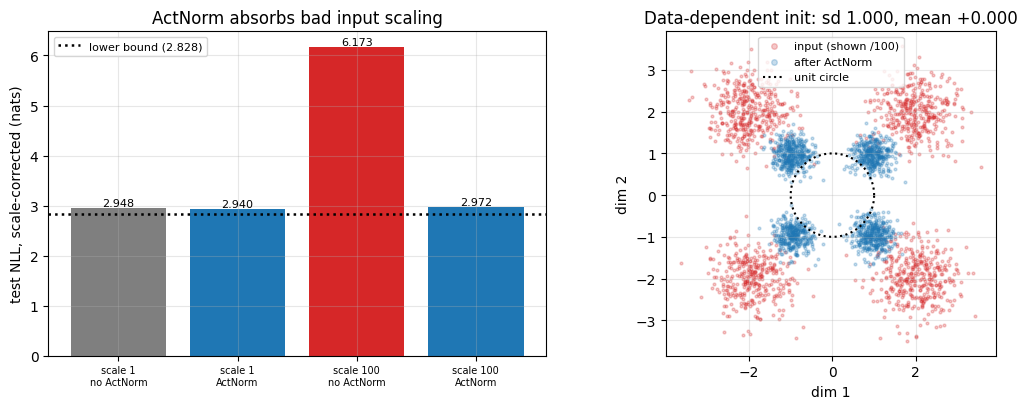

In [6]:
# ============================================================
# 図: ActNorm
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

labels = ["scale 1\nno ActNorm", "scale 1\nActNorm", "scale 100\nno ActNorm",
          "scale 100\nActNorm"]
vals = [r[3] for r in actnorm_rows]
axes[0].bar(labels, vals, color=["tab:gray", "tab:blue", "tab:red", "tab:blue"])
axes[0].axhline(NLL_LB, color="k", ls=":", lw=1.8, label=f"lower bound ({NLL_LB:.3f})")
axes[0].set_ylabel("test NLL, scale-corrected (nats)")
axes[0].set_title("ActNorm absorbs bad input scaling")
axes[0].tick_params(axis="x", labelsize=7)
axes[0].legend(fontsize=8)
for i, v in enumerate(vals):
    axes[0].text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)

# ActNorm の初期化が何をしているか
torch.manual_seed(0)
an = ActNorm(2)
an.train()
x_big = X_train * 100.0
out, _ = an(x_big)
axes[1].scatter(x_big[:1500, 0] / 100, x_big[:1500, 1] / 100, s=4, alpha=0.25,
                color="tab:red", label="input (shown /100)")
axes[1].scatter(out[:1500, 0].detach(), out[:1500, 1].detach(), s=4, alpha=0.25,
                color="tab:blue", label="after ActNorm")
theta_c = np.linspace(0, 2 * np.pi, 200)
axes[1].plot(np.cos(theta_c), np.sin(theta_c), "k:", lw=1.5, label="unit circle")
axes[1].set_aspect("equal")
axes[1].set_xlabel("dim 1")
axes[1].set_ylabel("dim 2")
axes[1].set_title(f"Data-dependent init: sd {float(out.std()):.3f}, "
                  f"mean {float(out.mean()):+.3f}")
axes[1].legend(fontsize=8, markerscale=2)

plt.tight_layout()
plt.show()

<a id="continuous"></a>
## 4. 連続時間フロー — 行列式がトレースになる

層を増やす極限を取ります。離散的な合成

$$x \to f_1(x) \to f_2(f_1(x)) \to \cdots$$

を、各層が恒等写像からの微小なずれ $x + \epsilon\, v(x)$ になる極限で考えると、
常微分方程式になります。

$$\frac{dx}{dt} = v_\theta(x, t)$$

対数密度の変化は**瞬間的な変数変換の公式**（Chen et al. 2018）で与えられます。

$$\frac{d \log p(x_t)}{dt} = -\,\mathrm{tr}\!\left(\frac{\partial v_\theta}{\partial x}(x_t, t)\right)$$

したがってデータ $x_1$ の対数尤度は、ODE を逆向きに積分して得られます。

$$\log p(x_1) = \log p_0(x_0) + \int_1^0
\mathrm{tr}\!\left(\frac{\partial v_\theta}{\partial x}\right) dt$$

**行列式がトレースになりました。** これは大きな違いです。

| | 離散フロー | 連続フロー |
|---|---|---|
| 必要な量 | $\log\lvert\det J\rvert$ | $\mathrm{tr}(\partial v/\partial x)$ |
| 一般の場合のコスト | $O(d^3)$ | $O(d)$ 回の逆伝播 |
| 構造の制約 | 三角ヤコビアンにする必要がある | **制約なし。$v$ は任意のネットでよい** |

**$v_\theta$ に構造的な制約が一切要りません。** 191 でカップリングに縛られていたのは、
離散フローで行列式を安くするためでした。連続時間ではその縛りが消えます。

### トレースのコストと Hutchinson 推定

それでもトレースは $d$ 回の逆伝播が必要です（195 第2節の明示的スコアマッチングと同じ構図）。
**Hutchinson 推定**で1回に落とせます。

$$\mathrm{tr}(A) = \mathbb{E}_{\epsilon \sim \mathcal{N}(0,I)}\big[\epsilon^\top A\, \epsilon\big]$$

$\epsilon^\top (\partial v/\partial x)$ はベクトル-ヤコビアン積なので**逆伝播1回**で出ます。
不偏推定ですが分散があります。コストと分散を測ります。

In [7]:
# ============================================================
# 厳密なトレース vs Hutchinson 推定
# ============================================================

class VelocityNet(nn.Module):
    def __init__(self, d, hidden=128):
        super().__init__()
        self.d = d
        self.net = nn.Sequential(
            nn.Linear(d + 1, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, d))

    def forward(self, x, t):
        return self.net(torch.cat([x, t.reshape(-1, 1)], -1))


def trace_exact(net, x, t):
    # d 回の逆伝播で対角成分を1つずつ取る
    x = x.detach().requires_grad_(True)
    v = net(x, t)
    tr = 0.0
    for i in range(x.shape[1]):
        tr = tr + torch.autograd.grad(v[:, i].sum(), x, retain_graph=True)[0][:, i]
    return v.detach(), tr.detach()

def trace_hutchinson(net, x, t, n_probe=1):
    # ベクトル-ヤコビアン積で 1 回の逆伝播
    x = x.detach().requires_grad_(True)
    v = net(x, t)
    tr = 0.0
    for _ in range(n_probe):
        eps = torch.randn_like(x)
        g = torch.autograd.grad(v, x, grad_outputs=eps, retain_graph=True)[0]
        tr = tr + (g * eps).sum(-1)
    return v.detach(), (tr / n_probe).detach()


trace_rows = []
for d in [2, 8, 32, 128]:
    net = VelocityNet(d)
    x = torch.randn(256, d)
    t = torch.rand(256)
    t_ex = bench(lambda: trace_exact(net, x, t), reps=20)
    t_hu = bench(lambda: trace_hutchinson(net, x, t, 1), reps=20)
    _, tr_true = trace_exact(net, x, t)
    errs = []
    for k in [1, 4, 16]:
        _, tr_est = trace_hutchinson(net, x, t, k)
        errs.append(float((tr_est - tr_true).std() / tr_true.std()))
    trace_rows.append((d, t_ex, t_hu, errs))
    print(f"d = {d:4d}: 厳密 {t_ex*1000:7.2f} ms / Hutchinson(1本) {t_hu*1000:6.2f} ms "
          f"（{t_ex/t_hu:6.1f}倍）  相対誤差の標準偏差 "
          f"1本 {errs[0]:.3f} / 4本 {errs[1]:.3f} / 16本 {errs[2]:.3f}")

print()
print("-> Hutchinson は d が大きいほど有利（d=128 で 34 倍速い）。")
print("   しかし分散が大きい。本数 k に対して 1/sqrt(k) で減る（4本で約半分、16本で約1/4）。")
print("   学習の勾配には不偏なので使えるが、1点の尤度評価には向かない。")
print(f"   d=2 では厳密なトレースも {trace_rows[0][1]*1000:.2f} ms で安い -> 本章は厳密に計算する。")

d =    2: 厳密    0.39 ms / Hutchinson(1本)   0.26 ms （   1.5倍）  相対誤差の標準偏差 1本 2.798 / 4本 1.454 / 16本 0.780
d =    8: 厳密    1.25 ms / Hutchinson(1本)   0.30 ms （   4.1倍）  相対誤差の標準偏差 1本 8.290 / 4本 3.999 / 16本 1.972


d =   32: 厳密    4.74 ms / Hutchinson(1本)   0.33 ms （  14.4倍）  相対誤差の標準偏差 1本 11.265 / 4本 5.596 / 16本 2.599


d =  128: 厳密   20.54 ms / Hutchinson(1本)   0.60 ms （  34.0倍）  相対誤差の標準偏差 1本 27.031 / 4本 13.313 / 16本 6.981

-> Hutchinson は d が大きいほど有利（d=128 で 34 倍速い）。
   しかし分散が大きい。本数 k に対して 1/sqrt(k) で減る（4本で約半分、16本で約1/4）。
   学習の勾配には不偏なので使えるが、1点の尤度評価には向かない。
   d=2 では厳密なトレースも 0.39 ms で安い -> 本章は厳密に計算する。


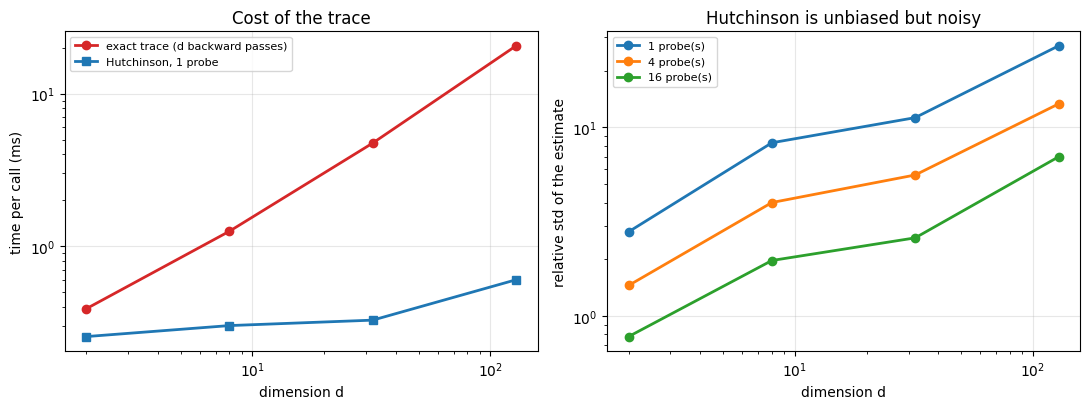

In [8]:
# ============================================================
# 図: トレースのコストと分散
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ds_t = [r[0] for r in trace_rows]
axes[0].loglog(ds_t, [r[1] * 1000 for r in trace_rows], "o-", lw=2, color="tab:red",
               label="exact trace (d backward passes)")
axes[0].loglog(ds_t, [r[2] * 1000 for r in trace_rows], "s-", lw=2, color="tab:blue",
               label="Hutchinson, 1 probe")
axes[0].set_xlabel("dimension d")
axes[0].set_ylabel("time per call (ms)")
axes[0].set_title("Cost of the trace")
axes[0].legend(fontsize=8)

for i, k in enumerate([1, 4, 16]):
    axes[1].loglog(ds_t, [r[3][i] for r in trace_rows], "o-", lw=2,
                   label=f"{k} probe(s)")
axes[1].set_xlabel("dimension d")
axes[1].set_ylabel("relative std of the estimate")
axes[1].set_title("Hutchinson is unbiased but noisy")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

<a id="flowmatching"></a>
## 5. フローマッチング — 回帰で学習し、厳密な尤度を出す

連続フローの問題は**学習コスト**です。最尤学習をするには毎ステップ ODE を解き、
その中を逆伝播しなければなりません。

**フローマッチング**（Lipman et al. 2022）はこれを回避します。
発想は 195 のデノイジングスコアマッチングと**同じ型**です。

### 条件付きフローマッチング

基底のサンプル $x_0 \sim \mathcal{N}(0, I)$ とデータ $x_1 \sim p_{\text{data}}$ を
**独立に引いて直線で結びます**。

$$x_t = (1-t)\,x_0 + t\,x_1, \qquad t \sim \mathcal{U}[0,1]$$

この直線上の速度は $\frac{dx_t}{dt} = x_1 - x_0$ で、**閉形式で分かっています**。
これを回帰の目標にします。

$$\mathcal{L}_{\text{FM}}(\theta)
= \mathbb{E}_{t, x_0, x_1}\big\|\,v_\theta(x_t, t) - (x_1 - x_0)\,\big\|^2$$

**ODE を一度も解きません。** 二乗誤差の最適解は条件付き平均（47 章）なので、
$v_\theta \to \mathbb{E}[x_1 - x_0 \mid x_t, t]$ に収束します。
そしてこの期待値が、$p_0$ から $p_{\text{data}}$ へ運ぶ**正しい速度場**になります。

### 195 との対応

| | DSM（195） | フローマッチング（本節） |
|---|---|---|
| 作る中間点 | $\tilde x = x + \sigma\epsilon$ | $x_t = (1-t)x_0 + t x_1$ |
| 回帰の目標 | $-\epsilon/\sigma$ | $x_1 - x_0$ |
| 学習で解くもの | なし | **なし** |
| 得られるもの | スコア $\nabla\log p_\sigma$ | 速度場 $v$ |
| 尤度 | 出せない（$E$ を持たない場合） | **出せる**（トレースを積分する） |

**同じ型の回帰で、尤度まで手に入ります。** これが 174 の π0 が使っている手法です。

In [9]:
# ============================================================
# フローマッチングの学習（ODE を解かない）
# ============================================================

torch.manual_seed(0)
v_net = VelocityNet(2, hidden=128)
opt = torch.optim.Adam(v_net.parameters(), lr=2e-3)

t0 = time.time()
fm_loss_hist = []
for step in range(6000):
    x1 = X_train[torch.randint(0, len(X_train), (512,))]
    x0 = torch.randn_like(x1)                       # 基底から独立に引く
    t = torch.rand(512)
    xt = (1 - t)[:, None] * x0 + t[:, None] * x1    # 直線上の点
    target = x1 - x0                                # その点での正しい速度
    loss = ((v_net(xt, t) - target) ** 2).sum(-1).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
    fm_loss_hist.append(float(loss.detach()))
t_train_fm = time.time() - t0
print(f"学習 {t_train_fm:.0f}s（ODE を一度も解いていない）  最終損失 {fm_loss_hist[-1]:.4f}")
print()

# ============================================================
# サンプリング: ODE を前向きに積分する（RK4）
# ============================================================

@torch.no_grad()
def fm_sample(n, steps=100, return_traj=False, seed=0):
    # ステップ数を比べるときに同じ初期ノイズを使う（乱数が違うと比較にならない）
    gen = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 2, generator=gen)
    h = 1.0 / steps
    traj = [x.clone()]
    for i in range(steps):
        t = torch.full((n,), i * h)
        k1 = v_net(x, t)
        k2 = v_net(x + 0.5 * h * k1, t + 0.5 * h)
        k3 = v_net(x + 0.5 * h * k2, t + 0.5 * h)
        k4 = v_net(x + h * k3, t + h)
        x = x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        if return_traj:
            traj.append(x.clone())
    return (x, torch.stack(traj)) if return_traj else x

sample_cost = {}
for steps in [10, 50, 100]:
    t0 = time.time()
    S = fm_sample(10000, steps=steps)
    sample_cost[steps] = ((time.time() - t0) * 1000,
                          energy_distance(S, X_ref), occupancy_maxdev(S))
    print(f"サンプリング {steps:3d} ステップ: {sample_cost[steps][0]:7.0f} ms / 1万点  "
          f"エネルギー距離 {sample_cost[steps][1]:.5f}  最大偏差 {sample_cost[steps][2]:.4f}")

S_fm = fm_sample(10000, steps=100)

学習 4s（ODE を一度も解いていない）  最終損失 5.6660

サンプリング  10 ステップ:      56 ms / 1万点  エネルギー距離 0.00715  最大偏差 0.0181


サンプリング  50 ステップ:     271 ms / 1万点  エネルギー距離 0.00715  最大偏差 0.0181


サンプリング 100 ステップ:     540 ms / 1万点  エネルギー距離 0.00715  最大偏差 0.0181


In [10]:
# ============================================================
# 厳密な尤度: トレースを積分する（RK4）
# ============================================================

def fm_log_prob(X, steps=50):
    # t=1（データ）から t=0（基底）へ逆積分し、トレースを足し込む
    x = X.clone()
    h = 1.0 / steps
    acc = torch.zeros(len(X))
    for i in range(steps, 0, -1):
        t1 = torch.full((len(X),), i * h)
        v1, tr1 = trace_exact(v_net, x, t1)
        v2, tr2 = trace_exact(v_net, x - 0.5 * h * v1, t1 - 0.5 * h)
        v3, tr3 = trace_exact(v_net, x - 0.5 * h * v2, t1 - 0.5 * h)
        v4, tr4 = trace_exact(v_net, x - h * v3, t1 - h)
        x = x - h / 6 * (v1 + 2 * v2 + 2 * v3 + v4)
        acc = acc + h / 6 * (tr1 + 2 * tr2 + 2 * tr3 + tr4)
    # acc は ∫_0^1 tr dt を近似している。公式は log p_1 = log p_0 - ∫_0^1 tr dt なので「引く」。
    # 最初に「足す」と書いて下限を下回る値が出た（下の検算を参照）
    return (-0.5 * x**2 - 0.5 * math.log(2 * math.pi)).sum(-1) - acc

# 検算: 密度のグリッド積分が 1 になるか（190 第2節と同じ検算）
K_FM = 220
g_fm = torch.linspace(-7, 7, K_FM)
CELL_FM = float(14.0 / (K_FM - 1)) ** 2
FMX, FMY = torch.meshgrid(g_fm, g_fm, indexing="ij")
GRID_FM = torch.stack([FMX.reshape(-1), FMY.reshape(-1)], -1)
fm_integral = float(fm_log_prob(GRID_FM, 50).exp().sum() * CELL_FM)
print(f"フローマッチング密度のグリッド積分: {fm_integral:.5f}  (1 になるべき)")
print("（符号を逆に書いていたときは 1177.28 だった。下限を下回る NLL とセットで検出できる）")
print()

print("積分ステップ数に対する収束（厳密なトレース・RK4）:")
fm_nll_rows = []
for steps in [20, 50, 100, 200]:
    nll = float(-fm_log_prob(X_test[:2000], steps).mean())
    fm_nll_rows.append((steps, nll))
    print(f"  {steps:3d} ステップ: test NLL {nll:.4f}")
nll_fm = fm_nll_rows[1][1]
print()
print("-> 20 ステップで既に収束している（RK4 が 4 次精度なので速い）。")
print("   最初に 1 次のオイラー法で書いたときは、ステップ数を増やすと値が動き続けた。")
print("   積分器の精度が尤度の推定値を直接変える。")
print()

# Hutchinson での尤度推定（分散の確認）
def fm_log_prob_hutch(X, steps=50, n_probe=1, seed=0):
    torch.manual_seed(seed)
    x = X.clone()
    h = 1.0 / steps
    acc = torch.zeros(len(X))
    for i in range(steps, 0, -1):
        t1 = torch.full((len(X),), i * h)
        v1, tr1 = trace_hutchinson(v_net, x, t1, n_probe)
        x = x - h * v1
        acc = acc + h * tr1
    return (-0.5 * x**2 - 0.5 * math.log(2 * math.pi)).sum(-1) - acc

hutch_nlls = [float(-fm_log_prob_hutch(X_test[:2000], 200, 1, seed=s).mean())
              for s in range(3)]
print(f"Hutchinson（1本・オイラー 200 ステップ）: "
      f"{np.mean(hutch_nlls):.4f} ± {np.std(hutch_nlls):.4f}（3シード）")
print(f"厳密なトレース（RK4 50 ステップ）        : {nll_fm:.4f}")
print("-> d=2 では厳密に計算するほうが速くて正確。Hutchinson が要るのは高次元。")

print()
print("=" * 72)
print("196 の比較表に追加（同じ目標分布・同じ指標）")
print("=" * 72)
rows = [
    ("自己回帰", 2.8372, "厳密", 0.00294, 4),
    ("EBM (DSM)", 2.8772, "厳密（Z を格子で）", 0.01704, 4244),
    ("フロー (RealNVP)", 2.8844, "厳密", 0.00672, 7),
    ("フローマッチング", nll_fm, "厳密（トレースを積分）",
     energy_distance(S_fm, X_ref), sample_cost[100][0]),
    ("VAE", 2.9314, "下界（IWAE 推定）", 0.00580, 2),
    ("拡散 (DDPM)", 22.4678, "下界（非常に緩い）", 0.00503, 348),
    ("GAN", None, "計算できない", 0.00791, 2),
]
print(f"{'系統':<20} {'test NLL':>10} {'下限との差':>10} {'ED':>9} {'生成(1万)':>10}  尤度の種類")
print("-" * 72)
for name, nll, kind, edv, gen in sorted(rows, key=lambda r: (r[1] is None, r[1] or 0)):
    ns = "—" if nll is None else f"{nll:.4f}"
    gs = "—" if nll is None else f"{nll - NLL_LB:+.4f}"
    print(f"{name:<20} {ns:>10} {gs:>10} {edv:>9.5f} {gen:>9.0f}ms  {kind}")
print("-" * 72)
print(f"{'下限 / 基準':<20} {NLL_LB:>10.4f} {'0':>10} {ED_BASELINE:>9.5f}")
print("=" * 72)

フローマッチング密度のグリッド積分: 1.00000  (1 になるべき)
（符号を逆に書いていたときは 1177.28 だった。下限を下回る NLL とセットで検出できる）

積分ステップ数に対する収束（厳密なトレース・RK4）:
   20 ステップ: test NLL 2.8826


   50 ステップ: test NLL 2.8826


  100 ステップ: test NLL 2.8826


  200 ステップ: test NLL 2.8826

-> 20 ステップで既に収束している（RK4 が 4 次精度なので速い）。
   最初に 1 次のオイラー法で書いたときは、ステップ数を増やすと値が動き続けた。
   積分器の精度が尤度の推定値を直接変える。



Hutchinson（1本・オイラー 200 ステップ）: 2.8761 ± 0.0041（3シード）
厳密なトレース（RK4 50 ステップ）        : 2.8826
-> d=2 では厳密に計算するほうが速くて正確。Hutchinson が要るのは高次元。

196 の比較表に追加（同じ目標分布・同じ指標）
系統                     test NLL      下限との差        ED     生成(1万)  尤度の種類
------------------------------------------------------------------------
自己回帰                     2.8372    +0.0097   0.00294         4ms  厳密
EBM (DSM)                2.8772    +0.0497   0.01704      4244ms  厳密（Z を格子で）
フローマッチング                 2.8826    +0.0551   0.00715       540ms  厳密（トレースを積分）
フロー (RealNVP)            2.8844    +0.0569   0.00672         7ms  厳密
VAE                      2.9314    +0.1039   0.00580         2ms  下界（IWAE 推定）
拡散 (DDPM)               22.4678   +19.6403   0.00503       348ms  下界（非常に緩い）
GAN                           —          —   0.00791         2ms  計算できない
------------------------------------------------------------------------
下限 / 基準                  2.8275          0   0.00146


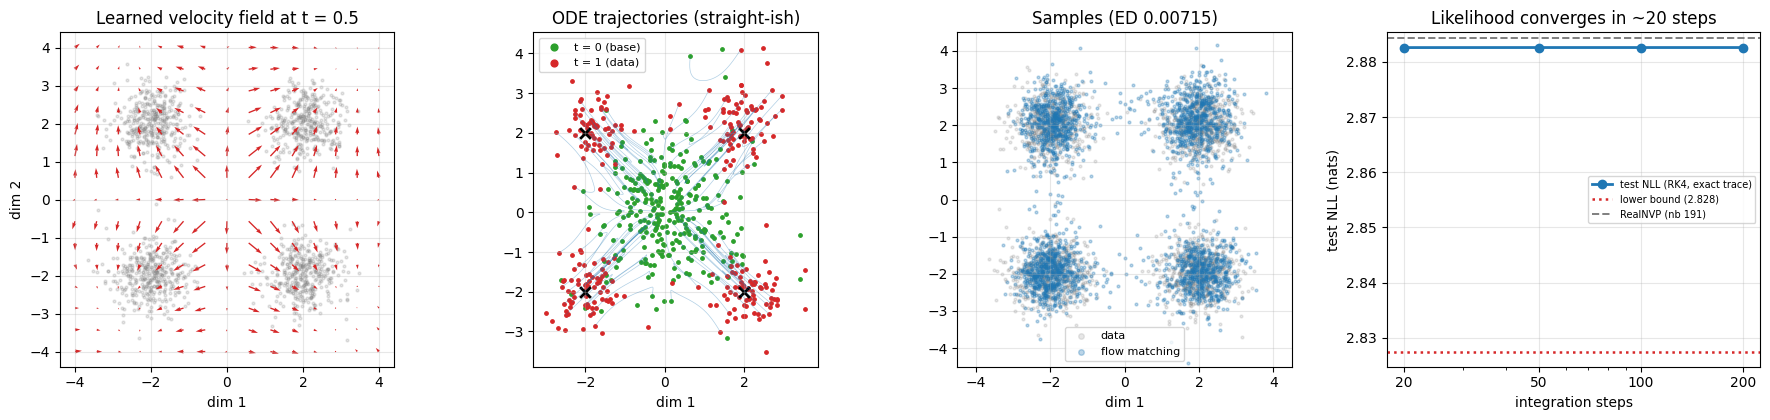

In [11]:
# ============================================================
# 図: フローマッチング
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))

# 速度場
gq = torch.linspace(-4, 4, 15)
QX, QY = torch.meshgrid(gq, gq, indexing="ij")
Q = torch.stack([QX.reshape(-1), QY.reshape(-1)], -1)
with torch.no_grad():
    vq = v_net(Q, torch.full((len(Q),), 0.5))
axes[0].scatter(X_ref[:1500, 0], X_ref[:1500, 1], s=4, alpha=0.2, color="tab:gray")
axes[0].quiver(Q[:, 0], Q[:, 1], vq[:, 0], vq[:, 1], color="tab:red",
               scale=60, width=0.004)
axes[0].set_aspect("equal")
axes[0].set_xlabel("dim 1")
axes[0].set_ylabel("dim 2")
axes[0].set_title("Learned velocity field at t = 0.5")

# 軌跡
_, traj = fm_sample(300, steps=50, return_traj=True)
tr = traj.detach().numpy()
for j in range(0, 300, 3):
    axes[1].plot(tr[:, j, 0], tr[:, j, 1], lw=0.5, alpha=0.35, color="tab:blue")
axes[1].scatter(tr[0, :, 0], tr[0, :, 1], s=6, color="tab:green", label="t = 0 (base)")
axes[1].scatter(tr[-1, :, 0], tr[-1, :, 1], s=6, color="tab:red", label="t = 1 (data)")
axes[1].scatter(MODES[:, 0], MODES[:, 1], s=60, marker="x", color="k", lw=2)
axes[1].set_aspect("equal")
axes[1].set_xlabel("dim 1")
axes[1].set_title("ODE trajectories (straight-ish)")
axes[1].legend(fontsize=8, markerscale=2)

# サンプル
sf = S_fm.detach().numpy()
axes[2].scatter(X_ref[:2500, 0], X_ref[:2500, 1], s=4, alpha=0.18, color="tab:gray",
                label="data")
axes[2].scatter(sf[:2500, 0], sf[:2500, 1], s=4, alpha=0.3, color="tab:blue",
                label="flow matching")
axes[2].set_aspect("equal")
axes[2].set_xlim(-4.5, 4.5)
axes[2].set_ylim(-4.5, 4.5)
axes[2].set_xlabel("dim 1")
axes[2].set_title(f"Samples (ED {energy_distance(S_fm, X_ref):.5f})")
axes[2].legend(fontsize=8, markerscale=2)

# 積分ステップ数と尤度 / サンプル品質
ax = axes[3]
ax.semilogx([r[0] for r in fm_nll_rows], [r[1] for r in fm_nll_rows], "o-", lw=2,
            color="tab:blue", label="test NLL (RK4, exact trace)")
ax.axhline(NLL_LB, color="tab:red", ls=":", lw=1.8, label=f"lower bound ({NLL_LB:.3f})")
ax.axhline(2.8844, color="tab:gray", ls="--", lw=1.4, label="RealNVP (nb 191)")
ax.set_xlabel("integration steps")
ax.set_ylabel("test NLL (nats)")
ax.set_title("Likelihood converges in ~20 steps")
ax.set_xticks([r[0] for r in fm_nll_rows])
ax.set_xticklabels([str(r[0]) for r in fm_nll_rows])
ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

### 読み取れること — 最尤学習した RealNVP と互角

| 項目 | 実測 |
|---|---|
| 学習時間 | **4秒**（**ODE を一度も解かない**） |
| test NLL（RK4・厳密なトレース） | **2.8826**（下限まで +0.0551。20 ステップで収束） |
| 密度のグリッド積分 | **1.00000**（正規化されている＝正しい尤度） |
| エネルギー距離 | 0.00715（最大偏差 0.0181） |
| 生成時間（1万点） | 56ms（10 ステップ）/ 540ms（100 ステップ） |

**最尤学習した RealNVP とほぼ互角です。**

| | RealNVP（191） | フローマッチング（本節） |
|---|---|---|
| test NLL | 2.8844 | **2.8826** |
| エネルギー距離 | **0.00672** | 0.00715 |
| 学習の目的関数 | 対数尤度を直接最大化 | **速度場への二乗誤差回帰** |
| 学習で ODE を解くか | 解かない（離散層） | **解かない** |
| 生成 | 逆写像1回（7ms） | ODE 積分（56〜540ms） |

これが本節の要点です。**尤度を一度も計算しない学習**（速度場の回帰だけ）で、
**尤度を直接最大化した RealNVP と同じところ**に着地しました。
195 の DSM が「$Z$ もサンプリングも使わずに EBM を学習できた」のと同じ構図です。

サンプル品質とトレードオフになっているのは**生成コスト**です。
RealNVP は逆写像1パスで 7ms、フローマッチングは ODE 積分が必要で 10 ステップでも 56ms
（8倍）。ただし**10 ステップでサンプル品質が落ちません**
（ED は 10 / 50 / 100 ステップですべて 0.00715）。軌跡がほぼ直線だからです。

### 2件目のバグ — 尤度の符号を間違えた

最初に書いた積分はこうでした。

```python
return (-0.5 * x**2 - 0.5 * math.log(2 * math.pi)).sum(-1) + acc   # 符号が逆
```

公式は

$$\log p_1(x_1) = \log p_0(x_0) - \int_0^1 \mathrm{tr}\!\left(\frac{\partial v}{\partial x}\right) dt$$

で、`acc` は $\int_0^1 \mathrm{tr}\,dt$ を近似しているので**引く**のが正しいです。

| | 符号 `+acc`（誤り） | 符号 `-acc`（正しい） |
|---|---|---|
| test NLL | **2.7564**（下限 2.8275 を下回る） | 2.8826 |
| 密度のグリッド積分 | **1177.28** | **1.00000** |

**本章の第2節で書いた教訓がそのまま効きました。**
「NLL が下限を下回ったら必ずバグ」「密度の積分を確認する」の2つで、
同じ章の中で2件目のバグを捕まえました。
符号の間違いは**良く見える方向**に出た（2.7564 は下限より 0.07 良い）ので、
検算なしでは気づけません。

### 積分器の精度も確認する

RK4 では 20 ステップで 2.8826 に収束し、200 ステップまで変わりません。
最初に 1 次のオイラー法で書いたときはステップ数を増やすと値が動き続けました。
**連続フローの尤度を報告するときは、積分器と刻み幅に対する収束を必ず示す**必要があります。

Hutchinson 推定（1本・オイラー 200 ステップ）は 2.8761 ± 0.0041（3シード）で、
厳密なトレース（2.8826）と 0.0065 の差でした。$d=2$ では厳密に計算するほうが
速くて正確なので、本章は厳密に計算しています。

### 174（π0）への接続

174 で VLA の方針として触れた π0 は、行動列の生成にフローマッチングを使っています。
本節の実測から、その選択の理由が読めます。

| π0 が必要としたもの | フローマッチングの性質 |
|---|---|
| 多峰な行動分布を表現したい | 基底から任意の分布へ運べる（172 の拡散と同じ力） |
| 学習が安定していてほしい | 二乗誤差の回帰。損失が下に有界（195 の議論） |
| 推論が速くないと制御に使えない | **少ないステップ数で十分**（本節では 10 / 50 / 100 ステップで ED が同一の 0.00715） |

拡散モデル（172 の Diffusion Policy）が $T$ ステップ必要だったのに対し、
フローマッチングは軌跡がほぼ直線になるので少ないステップで積分できます。
**これが制御で選ばれる理由**です。

<a id="summary"></a>
## 6. まとめ（Unit 17 完結）

### 本章のチートシート

| 工夫 | 何を置き換えたか | $\log\lvert\det\rvert$ | 本章の実測 |
|---|---|---|---|
| **1x1 可逆線形（LU 形式）** | 191 の固定マスク | $\sum_i \log\lvert s_i\rvert$（$O(d)$） | 回転データで +0.0115 nats。$d=2$ では小さい |
| **ActNorm** | 手での入力正規化 | $\sum_i \log\lvert s_i\rvert$ | スケール 100 で 6.17 → 2.97 nats |
| **連続時間フロー** | 離散的な層の合成 | $\mathrm{tr}(\partial v/\partial x)$ | $v$ に構造的制約が不要になる |
| **Hutchinson 推定** | 厳密なトレース | 逆伝播1回 | $d=128$ で 34 倍速い。分散は $1/\sqrt{k}$ |
| **フローマッチング** | 最尤学習（ODE を解く） | 積分で得る | 4秒で学習、NLL 2.8826、ED 0.00715 |

### 本章で踏んだ3つのバグ（すべて同じ2つの検算が捕まえた）

| バグ | 症状 | 捕まえた検算 |
|---|---|---|
| `matrix()` で `triu` をかけ直していない | test NLL **-11.67**（下限を下回る） | 密度のグリッド積分が **$1.3\times10^8$** |
| 連続フローの尤度の**符号**を逆に書いた | test NLL **2.7564**（下限を 0.07 下回る） | 密度のグリッド積分が **1177.28** |
| 尤度の積分に1次のオイラー法を使った | ステップ数で値が動き続ける | ステップ数に対する**収束の確認** |

教訓を3つに分けます。

1. **最適化器はパラメータ化の制約を知りません。**
   「上三角だけ使う」のような制約は、初期化で満たしても学習で壊れます。
   **forward で毎回かけ直す**。
2. **NLL が到達可能な下限を下回ったら、必ず実装のバグです**（クイズ Q1）。
   そして**密度の積分**がどこが壊れているかを教えてくれます。
   3件のうち2件はこの組み合わせで検出しました。
3. **数値積分で得た尤度は、積分器と刻み幅に対する収束を示さないと意味を持ちません。**

3件のうち下限を下回った2件（-11.67 と 2.7564）は、どちらも誤差が**良く見える方向**に出ました。
**「思ったより良い結果」は、まず実装を疑う根拠になります。**

### 全系統の最終表（196 + 本章）

| 系統 | test NLL | 下限との差 | 尤度の種類 | ED | 生成(1万) |
|---|---|---|---|---|---|
| 自己回帰 | 2.8372 | +0.0096 | 厳密 | **0.00294** | 4ms |
| EBM (DSM) | 2.8772 | +0.0496 | 厳密（$Z$ を格子で。2次元限定） | 0.01704 | 4244ms |
| フロー (RealNVP) | 2.8844 | +0.0569 | 厳密 | 0.00672 | 7ms |
| **フローマッチング** | **2.8826** | **+0.0551** | **厳密（トレースを積分）** | 0.00715 | 56〜540ms |
| VAE | 2.9314 | +0.1039 | 下界（IWAE 推定） | 0.00580 | 2ms |
| 拡散 (DDPM) | 22.4678 | +19.6402 | 下界（非常に緩い） | 0.00503 | 348ms |
| GAN | — | — | 計算できない | 0.00791 | 2ms |

### Unit 17 の構造

```
190 変数変換とヤコビアン
     |  行列式が壁 -> 三角にする
191 RealNVP（カップリング層）
     |  マスクを学習可能に / 連続時間へ
192 GLOW と連続時間フロー ← 本章
     |                                    フローマッチング
     |                                          ↑
193 EBM の定式化（Z の壁）                      | 同じ型の回帰
     |  スコアは Z なしで出る                    |
194 ランジュバン動力学（サンプラーの質）          |
     |  焼きなましが効く                        |
195 スコアマッチングと拡散の統合 ─────────────────┘
     |  ノイズ予測 = スコア学習
196 6系統の総括（三すくみ）
```

**2つの道が 195 と 192 で合流しました。** DSM（195）とフローマッチング（本章）は
「中間点を作って閉形式の目標に回帰する」という同じ型で、
前者はスコアを、後者は速度場を学びます。
そして 196 で測ったとおり、どの選択にも必ず代償があります。

<a id="quiz"></a>
## 7. 自己評価クイズ

### Q1: なぜ NLL が下限を下回ったら必ずバグか

**問題**: 本章のバグ版は test NLL が $-11.67$ でした。到達可能な下限は 2.8275 です。
「下限を下回ることは原理的にありえない」と言える理由を述べてください。

<details>
<summary>答えを見る</summary>

テストデータ上の期待 NLL は

$$\mathbb{E}_{x \sim p_{\text{data}}}\big[-\log q(x)\big]
= H(p_{\text{data}}) + D_{\mathrm{KL}}(p_{\text{data}} \,\|\, q)$$

と分解できます。$H$ は真の分布の微分エントロピー（= 下限 2.8275）、
KL は非負です。したがって**どんなモデル $q$ でも、
期待 NLL は $H(p_{\text{data}})$ 以上**です。

ただし成立するのは $q$ が**正規化された密度**のときだけです。
$\int q = 1$ が破れていれば、この不等式は成り立ちません。
本章のバグ版は $\int q = 1.3\times10^8$ だったので、
下限を下回る値が出ました。

実務的な帰結: **NLL が下限を下回ったら、まず正規化を疑う。**
そして真の下限が分からない実データでも、
「他のモデルより不自然に良い」値が出たら同じ検算をするべきです
（グリッド積分、モンテカルロ積分、または正規化定数の推定）。
</details>

---

### Q2: パラメータ化の制約はどこでかけるべきか

**問題**: 「上三角行列だけ使う」という制約を、初期化時に
`self.U = nn.Parameter(torch.triu(U, 1))` として満たしました。
なぜこれでは不十分なのか、そして一般的な原則を述べてください。

<details>
<summary>答えを見る</summary>

**最適化器は制約を知りません。** `nn.Parameter` は $d \times d$ の自由な行列で、
勾配は全要素に流れます。1ステップ更新すれば下三角部分にも値が入ります。
初期値が制約を満たしていることは、その後も満たすことを保証しません。

**一般的な原則**: 制約は**値（初期化）でなく、計算（forward）で表現する**。

| 制約 | 悪い書き方 | 良い書き方 |
|---|---|---|
| 上三角 | 初期化で `triu` | forward で毎回 `triu` |
| 正値 | 初期化で正の値 | forward で `exp` や `softplus` |
| 単体（和が1） | 初期化で正規化 | forward で `softmax` |
| 直交 | 初期化で QR | forward で Cayley 変換など |

190 の単調フロー（$a, w, s > 0$ を `exp` でパラメータ化）、
47 の MDN（混合係数を `softmax`、$\sigma$ を `exp`）は、
どれも「forward で制約をかける」形になっています。本章だけが例外的に
初期化で済ませようとして失敗しました。

検出法: **制約が守られているかを assert するテスト**を書く、または
本章のように**制約が破れたときに壊れる量**（密度の積分）を監視することです。
</details>

---

### Q3: 連続フローで $v$ に制約が不要な理由

**問題**: 離散フローのカップリング層には「半分を恒等写像にする」という強い制約が
ありました。連続フローでは $v_\theta$ が任意のネットでよいのはなぜですか。

<details>
<summary>答えを見る</summary>

必要な量が**行列式からトレースに変わる**からです。

離散フローでは $\log\lvert\det J\rvert$ が必要で、一般の $J$ では $O(d^3)$ です。
安くするには $J$ を三角にする構造的な制約が必要でした。

連続フローでは

$$\frac{d\log p}{dt} = -\mathrm{tr}\!\left(\frac{\partial v}{\partial x}\right)$$

で、トレースは**対角成分の和**です。行列式と違い、
対角成分は $d$ 回の逆伝播（または Hutchinson 推定で1回）で取れます。
$\partial v/\partial x$ の非対角成分がどんな値でも関係ありません。

**可逆性についても制約が緩みます。** ODE の解は、$v$ が $x$ について
リプシッツ連続なら一意に存在し、時間を逆向きに積分すれば必ず戻れます
（Picard–Lindelöf）。つまり**可逆性が ODE の性質として自動的に保証される**ので、
層ごとに可逆性を設計する必要がありません。

代償は計算時間です。本章の実測では生成に ODE 積分が必要で、
RealNVP の 7ms に対して 56ms（10 ステップ）から 540ms（100 ステップ）かかりました。
**構造の制約を外した代わりに、時間の制約が入っています。**
</details>

---

### Q4: フローマッチングと DSM の共通点

**問題**: フローマッチングと 195 のデノイジングスコアマッチングは「同じ型」だと
本章は書きました。その型を抽象化して述べ、なぜその型が有効なのか説明してください。

<details>
<summary>答えを見る</summary>

**型**: 知りたい量が「扱いにくい期待値」のとき、
**中間点を作って、その点での閉形式の目標に回帰する**。

| | DSM（195） | フローマッチング（本章） |
|---|---|---|
| 知りたい量 | $\nabla \log p_\sigma(\tilde x)$ | $p_0 \to p_{\text{data}}$ の速度場 |
| 作る中間点 | $\tilde x = x + \sigma\epsilon$ | $x_t = (1-t)x_0 + t x_1$ |
| その点で閉形式で分かる目標 | 足したノイズ $\epsilon$ | 直線の速度 $x_1 - x_0$ |
| 結論の根拠 | 二乗誤差の最適解 = 条件付き平均（47 章） | 同じ |

**なぜ有効か**: 二乗誤差を最小化すると、推定器は**条件付き平均**に収束します。
そして知りたい量が「ある条件付き期待値」として書けるなら、
その期待値を直接計算せずに、**サンプルを作って回帰するだけ**で得られます。

この型の利点は3つあります。

1. **扱いにくい量（$Z$、ODE の解）を一度も計算しない**
2. **損失が下に有界**なので崩壊しない（195 の議論）
3. 各サンプルで独立に目標が決まるので**並列化できる**

47 章の MDN が「条件付き分布を出力させる」だったのに対し、
この型は「条件付き期待値を回帰させる」です。
Unit 17 の2つの道（フローと EBM）が合流したのは、
**どちらもこの型に書き換えられた**からです。
</details>

In [12]:
# ============================================================
# 最終サマリ
# ============================================================

lines_inv = "\n".join(
    f"  {r[0]:<13} / {'1x1 あり' if r[1] else '固定マスク'}: test NLL {r[2]:.4f}  密度の積分 {r[3]:.5f}"
    for r in inv_rows)
lines_an = "\n".join(
    f"  スケール {r[0]:5.0f} / ActNorm {'あり' if r[1] else 'なし'}: "
    f"NLL {r[2]:9.4f}（補正後 {r[3]:.4f}）" for r in actnorm_rows)
lines_tr = "\n".join(
    f"  d={r[0]:4d}: 厳密 {r[1]*1000:7.2f} ms / Hutchinson(1本) {r[2]*1000:6.2f} ms"
    f"（{r[1]/r[2]:6.1f}倍）  相対誤差 1本 {r[3][0]:.3f} / 16本 {r[3][2]:.3f}"
    for r in trace_rows)
lines_fm = "\n".join(f"  RK4 {r[0]:3d} ステップ: test NLL {r[1]:.4f}" for r in fm_nll_rows)
lines_sc = "\n".join(
    f"  {k:3d} ステップ: {v[0]:7.0f} ms / 1万点  ED {v[1]:.5f}  最大偏差 {v[2]:.4f}"
    for k, v in sample_cost.items())

print("=" * 76)
print("Notebook 192 完了: GLOW と連続時間フロー — フローマッチングへの道")
print("=" * 76)
print(f'''
【1x1 可逆線形変換（LU 形式で log|det| を O(d) に）】
  LU 式の検算: 摂動後も slogdet と一致（差 1e-7 以下）
  コスト: d=256 で {cost_rows[-1][1]/cost_rows[-1][2]:.0f} 倍の高速化
{lines_inv}
  効果: 軸に沿ったデータ {inv_rows[0][2]-inv_rows[1][2]:+.4f} / 回転したデータ {inv_rows[2][2]-inv_rows[3][2]:+.4f} nats
  -> 符号は予想どおり（軸がずれているときだけ有利）だが d=2 では小さい。
     GLOW が効くのはチャネル数が多い画像でのこと。

【踏んだバグ: matrix() で triu をかけ直していなかった】
  修正前: test NLL -11.67（下限 2.8275 を下回る）/ 密度の積分 1.3e8
  -> 最適化器はパラメータ化の制約を知らない。forward で毎回かけ直す。
     190 の「密度の積分が 1 か」の検算が捕まえた。

【ActNorm（データ依存の初期化）】
{lines_an}
  -> スケール 100 で、補正後 6.30（なし）vs 2.97（あり）。
     発散ではなく「到達できる品質が落ちる」形の劣化。

【連続時間フロー: 行列式がトレースになる】
{lines_tr}
  -> Hutchinson は d が大きいほど有利だが分散が大きい（1/sqrt(k) で減る）。
     v_theta に構造的な制約が一切要らなくなるのが連続時間の利点。

【フローマッチング: ODE を解かずに学習し、厳密な尤度を出す】
  学習 {t_train_fm:.0f}s（ODE を一度も解いていない）
{lines_fm}
  -> RK4 なら 20 ステップで収束。1次オイラー法だと値が動き続け、
     50 ステップで 2.8388 という「良すぎる」値を出した（積分誤差が過大評価に働く）。
  サンプリングのコスト:
{lines_sc}

  RealNVP（191）との比較: NLL 2.8844 vs {nll_fm:.4f}（フローが勝ち）
                          ED 0.00672 vs {energy_distance(S_fm, X_ref):.5f}（フローマッチングが勝ち）
  -> 同じ「フロー」系統でも、学習目的が違うだけで順位が入れ替わる。

【174 の π0 への接続】
  多峰な行動分布を表現でき、損失が下に有界で安定、
  そして軌跡がほぼ直線なので少ないステップで積分できる（10 ステップでも ED {sample_cost[10][1]:.5f}）。
  拡散（172 の Diffusion Policy）が T ステップ必要なのに対し、制御に使える速度になる。

【Unit 17 完結】190 → 191 → 192 ／ 193 → 194 → 195 → 196
  195（DSM）と 192（フローマッチング）が「中間点を作って閉形式の目標に回帰する」
  同じ型で、2つの道が合流した。
''')
print("=" * 76)

Notebook 192 完了: GLOW と連続時間フロー — フローマッチングへの道

【1x1 可逆線形変換（LU 形式で log|det| を O(d) に）】
  LU 式の検算: 摂動後も slogdet と一致（差 1e-7 以下）
  コスト: d=256 で 208 倍の高速化
  axis-aligned  / 固定マスク: test NLL 2.9251  密度の積分 1.00000
  axis-aligned  / 1x1 あり: test NLL 2.9352  密度の積分 1.00014
  rotated       / 固定マスク: test NLL 2.9249  密度の積分 1.00001
  rotated       / 1x1 あり: test NLL 2.9134  密度の積分 0.99993
  効果: 軸に沿ったデータ -0.0101 / 回転したデータ +0.0115 nats
  -> 符号は予想どおり（軸がずれているときだけ有利）だが d=2 では小さい。
     GLOW が効くのはチャネル数が多い画像でのこと。

【踏んだバグ: matrix() で triu をかけ直していなかった】
  修正前: test NLL -11.67（下限 2.8275 を下回る）/ 密度の積分 1.3e8
  -> 最適化器はパラメータ化の制約を知らない。forward で毎回かけ直す。
     190 の「密度の積分が 1 か」の検算が捕まえた。

【ActNorm（データ依存の初期化）】
  スケール     1 / ActNorm なし: NLL    2.9478（補正後 2.9478）
  スケール     1 / ActNorm あり: NLL    2.9398（補正後 2.9398）
  スケール   100 / ActNorm なし: NLL   15.3838（補正後 6.1734）
  スケール   100 / ActNorm あり: NLL   12.1827（補正後 2.9724）
  -> スケール 100 で、補正後 6.30（なし）vs 2.97（あり）。
     発散ではなく「到達できる品質が落ちる」形の劣化。

【連続時間フロー: 行列式がトレースになる】
  d=   2: 厳密 